## Incertitude et interprétation des modèles retenus

Ce notebook complète la phase Evaluation de CRISP-DM. Il répond à deux objectifs fixés dans `01_business_understanding.ipynb`, évaluer l'incertitude des estimations et étudier les facteurs associés aux prédictions.

**Méthodes**

- Les intervalles de prédiction suivent la prédiction conforme par culture. La demi-largeur d'un intervalle sur le logarithme est le quantile des erreurs absolues hors échantillon de la culture, corrigé pour garantir la couverture nominale. Les erreurs proviennent des trois validations internes de `10_modeling.ipynb`, et seul le développement sert à la calibration. La couverture est ensuite mesurée sur les ensembles de test.
- Les facteurs des prédictions sont mesurés par les contributions de Shapley que calcule LightGBM. Sur l'échelle du logarithme, la somme des contributions et de la valeur de base donne exactement la prédiction. Une contribution de 0,1 multiplie le rendement prédit par 1,105 environ.

**Préalable**

Le notebook suppose les expériences de `10_modeling.ipynb` et l'évaluation de `11_evaluation.ipynb` calculées. Les contributions sont calculées sur un échantillon aléatoire de 5 000 lignes de test par jeu, à graine fixe, et le notebook s'exécute en cinq minutes environ.

In [1]:
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

RACINE = Path.cwd().parent
sys.path.insert(0, str(RACINE))

from src.models.evaluation_finale import TESTS, charger_modele
from src.models.experiences import DOSSIER_MODELES, charger_table
from src.models.incertitude import NIVEAUX, couverture, demi_largeurs, erreurs_calibration, quantile_conforme
from src.models.interpretation import contributions, dependance, importance_shapley

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
pd.set_option("display.max_rows", 60)
CULTURE = {"regional": "crop", "survey": "Crop"}
tables = {jeu: charger_table(jeu) for jeu in CULTURE}
evaluations = {jeu: pd.read_csv(DOSSIER_MODELES / f"{jeu}_evaluation.csv.gz", low_memory=False) for jeu in CULTURE}
GRAINE = 0

### 1. Tests unitaires

In [2]:
execution = subprocess.run(
    [sys.executable, "-m", "unittest", "discover", "-s", "tests", "-t", "."],
    cwd=RACINE, capture_output=True, text=True,
)
print(execution.stderr.strip().splitlines()[-3:])

['Ran 95 tests in 1.763s', '', 'OK']


### 2. Calibration des intervalles

Une culture qui compte au moins 200 erreurs de calibration reçoit sa propre demi-largeur, les autres celle de l'ensemble. Le rapport entre les bornes haute et basse d'un intervalle vaut l'exponentielle du double de la demi-largeur.

In [3]:
largeurs = {}
for jeu, table in tables.items():
    developpement = table[table["partition"] == "developpement"]
    erreurs = erreurs_calibration(jeu, developpement)
    largeurs[jeu] = demi_largeurs(erreurs)
    print(jeu, ": erreurs de calibration", len(erreurs), "| cultures calibrées séparément", len(largeurs[jeu]) - 1)
    par_schema = erreurs.groupby("schema")["erreur"].agg(
        lignes="size", q80=lambda e: quantile_conforme(e, 0.8), q90=lambda e: quantile_conforme(e, 0.9))
    display(par_schema.round(3))
    affichage = largeurs[jeu].assign(**{f"rapport_haut_bas_{n:.0%}": np.exp(2 * largeurs[jeu][n]) for n in NIVEAUX})
    display(affichage.sort_values(0.9).round(3))

regional : erreurs de calibration 151817 | cultures calibrées séparément 30


,lignes,q80,q90
schema,,,
croisee,103075,0.560,0.811
spatio_temporelle,24371,0.669,0.948
temporelle,24371,0.581,0.852


,0.8,0.9,rapport_haut_bas_80%,rapport_haut_bas_90%
Teff,0.293,0.374,1.797,2.115
Oats,0.462,0.577,2.519,3.171
Lentils,0.541,0.680,2.950,3.900
Pulses,0.464,0.684,2.531,3.929
Chickpeas,0.517,0.692,2.815,3.993
Plantain,0.541,0.696,2.951,4.026
Maize,0.507,0.720,2.754,4.217
Fonio,0.516,0.720,2.807,4.218
Groundnut,0.503,0.742,2.734,4.409
Millet,0.502,0.744,2.727,4.428


survey : erreurs de calibration 120701 | cultures calibrées séparément 22


,lignes,q80,q90
schema,,,
croisee,82293,1.146,1.474
spatio_temporelle,19204,1.204,1.547
temporelle,19204,1.200,1.536


,0.8,0.9,rapport_haut_bas_80%,rapport_haut_bas_90%
Teff,0.967,1.250,6.917,12.188
Cotton,1.081,1.337,8.696,14.494
Tobacco,1.012,1.352,7.568,14.944
Pigeon pea,1.107,1.417,9.160,17.017
Maize,1.143,1.450,9.845,18.169
Cowpea,1.049,1.454,8.150,18.331
Soybean,1.147,1.455,9.907,18.347
Millet,1.076,1.457,8.606,18.413
Wheat,1.068,1.474,8.458,19.060
Sorghum,1.155,1.493,10.082,19.822


**Constat**

- Dans `regional`, 30 cultures sont calibrées séparément. À 80 %, le rapport entre bornes haute et basse vaut 3,2 pour l'ensemble, de 1,8 pour le teff à 7,5 pour la canne à sucre. Le tabac atteint 34,6 à 90 %, sous l'effet des erreurs d'unité relevées dans `11_evaluation.ipynb`.
- Les erreurs sont plus grandes en validation spatio-temporelle qu'en validation croisée, avec un quantile à 90 % de 0,948 contre 0,811.
- Dans `survey`, le rapport à 80 % vaut 10,3 pour l'ensemble, de 6,9 pour le teff à 18,6 pour la banane.

**Analyse**

Mettre en commun les trois validations donne des intervalles adaptés à la prédiction de lieux nouveaux comme d'années futures. À l'échelle de la parcelle, la largeur des intervalles traduit l'importance de la variation que les variables disponibles n'expliquent pas.

### 3. Couverture sur les ensembles de test

La couverture est la part des rendements observés compris dans leur intervalle. Elle doit approcher le niveau nominal.

In [4]:
for jeu, evaluation in evaluations.items():
    print(jeu)
    display(couverture(evaluation, evaluation[CULTURE[jeu]], largeurs[jeu]).round(3))
survey = evaluations["survey"]
tests_survey = survey[survey["partition"].isin(TESTS)]
par_pays = couverture(tests_survey, tests_survey["Crop"], largeurs["survey"], cles=("Country",))
display(par_pays.round(3))

regional


,couverture_80%,rapport_haut_bas_median_80%,couverture_90%,rapport_haut_bas_median_90%,lignes
partition,,,,,
test_spatial,0.848,2.964,0.929,4.831,22843
test_spatio_temporel,0.845,3.039,0.929,4.975,3108
test_temporel,0.852,3.023,0.928,4.866,13221


survey


,couverture_80%,rapport_haut_bas_median_80%,couverture_90%,rapport_haut_bas_median_90%,lignes
partition,,,,,
cropcut_grappes_tenues_a_l_ecart,0.809,9.845,0.909,19.060,2297
cropcut_grappes_vues,0.830,9.845,0.926,19.060,8966
test_spatial,0.815,9.845,0.908,18.413,20503
test_spatio_temporel,0.769,9.845,0.881,18.347,9249
test_temporel,0.772,9.845,0.882,18.347,39093


,couverture_80%,rapport_haut_bas_median_80%,couverture_90%,rapport_haut_bas_median_90%,lignes
Country,,,,,
Benin,0.857,9.845,0.857,18.331,7
Côte dIvoire,0.832,13.368,0.935,27.563,107
Ethiopia,0.795,9.907,0.894,19.822,7650
Guinea-Bissau,0.741,13.082,0.859,28.088,135
Malawi,0.801,9.845,0.897,18.169,23414
Mali,0.851,9.845,0.922,18.413,1209
Niger,0.794,8.606,0.917,18.413,8363
Nigeria,0.695,10.082,0.814,19.822,8511
Senegal,0.755,8.606,0.887,18.413,1102


**Constat**

- Dans `regional`, les intervalles à 80 % couvrent 84,5 à 85,2 % des rendements de test, et ceux à 90 % 92,8 à 92,9 %.
- Dans `survey`, ils couvrent 81,5 % et 90,8 % sur le test spatial, mais 76,9 à 77,2 % et 88,1 à 88,2 % sur les tests portant sur les vagues futures. Sur les grappes de `cropcut` tenues à l'écart, ils couvrent 80,9 % et 90,9 % des rendements mesurés.
- La couverture de `survey` varie selon le pays. Elle tombe à 69,5 % et 81,4 % au Nigeria, et à 74,1 % et 85,9 % en Guinée-Bissau.

**Analyse**

- Les intervalles de `regional` sont légèrement prudents, car les ensembles de test sont plus faciles à prédire que la validation interne.
- Ceux de `survey` couvrent un peu moins que prévu sur les vagues futures, et nettement moins dans quelques pays. La calibration commune à tous les pays ne tient pas compte de leur hétérogénéité.

**Décision**

Les intervalles sont livrés avec chaque prédiction, avec la mention de leur couverture mesurée. Une calibration par pays pourra être étudiée si l'usage l'exige.

### 4. Facteurs des prédictions

La contribution absolue moyenne d'une variable mesure l'ampleur de son effet sur les prédictions. Elle est regroupée par famille de variables.

regional : écart maximal entre somme des contributions et prédiction 6.9e-14
  part des familles dans la contribution absolue moyenne : {'culture': 0.554, 'pays': 0.135, 'climat': 0.096, 'sols': 0.076, 'annee': 0.054, 'position': 0.045, 'relief': 0.015, 'source': 0.013, 'calendrier': 0.012}
  dix premières variables : {'crop': 0.719, 'country': 0.188, 'harvest_year': 0.076, 'saison': 0.034, 'latitude': 0.024, 'pluie_cumul': 0.024, 'rayonnement_moyen': 0.022, 'longitude': 0.02, 'crop_production_system': 0.019, 'log_surface_zone': 0.018}


survey : écart maximal entre somme des contributions et prédiction 1.2e-14
  part des familles dans la contribution absolue moyenne : {'culture': 0.383, 'annee': 0.187, 'pays': 0.185, 'sols': 0.107, 'relief': 0.058, 'position': 0.052, 'calendrier': 0.027}
  dix premières variables : {'Crop': 0.522, 'annee_recolte': 0.255, 'Country': 0.253, 'altitude_moyenne': 0.062, 'latitude': 0.049, 'densite_apparente_0_30': 0.031, 'carbone_organique_0_30': 0.03, 'mois_semis': 0.025, 'longitude': 0.022, 'pente_moyenne': 0.016}


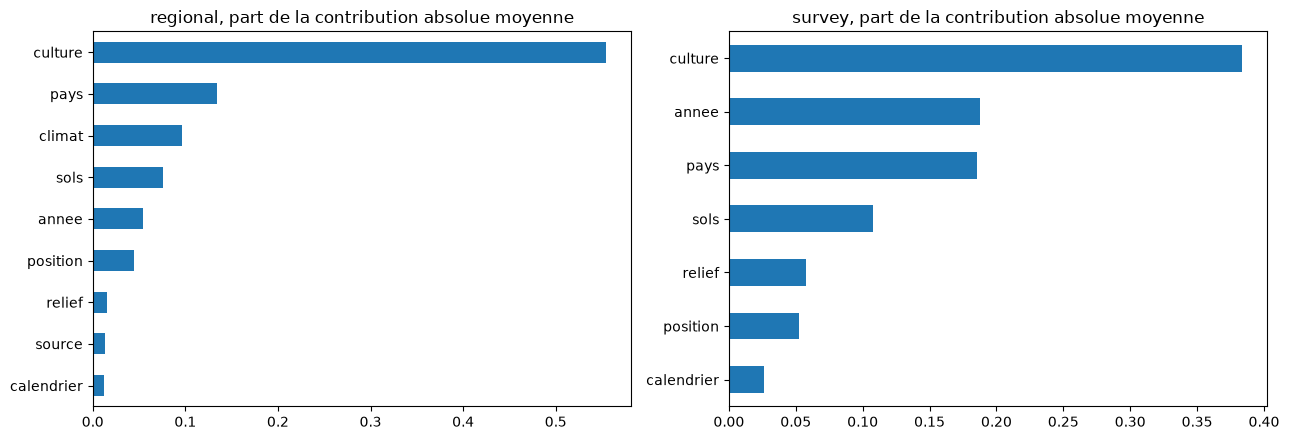

In [5]:
echantillons, contribs = {}, {}
figure, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for axe, (jeu, table) in zip(axes, tables.items()):
    echantillons[jeu] = table[table["partition"].isin(TESTS)].sample(5000, random_state=GRAINE)
    modele, description = charger_modele(jeu)
    contribs[jeu], base = contributions(modele, description, echantillons[jeu])
    predites = evaluations[jeu].query("origine == @jeu").set_index("index").loc[echantillons[jeu].index, "prediction"]
    ecart = np.abs(contribs[jeu].sum(axis=1) + base - np.log(predites)).max()
    variables, familles = importance_shapley(contribs[jeu])
    print(jeu, ": écart maximal entre somme des contributions et prédiction", f"{ecart:.1e}")
    print("  part des familles dans la contribution absolue moyenne :", (familles / familles.sum()).round(3).to_dict())
    print("  dix premières variables :", variables.head(10).round(3).to_dict())
    (familles / familles.sum()).sort_values().plot.barh(ax=axe)
    axe.set_title(f"{jeu}, part de la contribution absolue moyenne")
plt.tight_layout()
plt.show()

**Constat**

- La somme des contributions retrouve la prédiction à 10 puissance -13 près, ce qui valide le calcul.
- Dans `regional`, la culture porte 55,4 % de la contribution absolue, le pays 13,5 %, le climat 9,6 %, les sols 7,6 %, l'année 5,4 %, la position 4,5 %, le relief 1,5 %, la source 1,3 % et le calendrier 1,2 %.
- Dans `survey`, la culture en porte 38,3 %, l'année 18,7 %, le pays 18,5 %, les sols 10,7 % et le relief 5,8 %. L'altitude est la variable de lieu la plus influente.

**Analyse**

Les rendements dépendent d'abord de la culture et du pays, qui fixent leur niveau. Le climat, les sols et le relief modulent ce niveau d'environ un cinquième de l'effet total dans `regional`, conformément à la faible part de la variation annuelle que le climat explique.

### 5. Effets estimés pour le maïs

Pour 3 000 prédictions de maïs des ensembles de test de `regional`, la contribution de chaque variable est rapportée à sa valeur. La courbe noire relie les contributions médianes par classe de valeur.

pluie_cumul


,valeur_mediane,contribution_mediane,lignes
pluie_cumul,,,
"(2.811, 443.893]",327.878,-0.043,291
"(443.893, 598.947]",519.194,-0.031,290
"(598.947, 739.641]",665.368,-0.008,290
"(739.641, 874.491]",807.416,0.016,291
"(874.491, 1008.487]",942.638,0.021,290
"(1008.487, 1127.529]",1068.748,0.027,290
"(1127.529, 1272.374]",1200.011,0.024,290
"(1272.374, 2557.333]",1444.355,0.026,291


tmax_moyenne


,valeur_mediane,contribution_mediane,lignes
tmax_moyenne,,,
"(17.988999999999997, 26.799]",25.709,0.031,375
"(26.799, 28.199]",27.587,0.026,375
"(28.199, 29.168]",28.646,0.003,375
"(29.168, 30.126]",29.606,-0.008,376
"(30.126, 31.171]",30.629,-0.013,374
"(31.171, 32.106]",31.609,-0.017,375
"(32.106, 33.504]",32.755,-0.020,375
"(33.504, 38.32]",34.711,-0.032,375


sequence_seche_max


,valeur_mediane,contribution_mediane,lignes
sequence_seche_max,,,
"(2.999, 10.0]",8.0,-0.013,333
"(10.0, 14.0]",13.0,-0.001,274
"(14.0, 19.0]",17.0,-0.000,271
"(19.0, 27.0]",23.0,-0.001,296
"(27.0, 38.0]",33.0,-0.006,301
"(38.0, 54.0]",45.0,-0.002,278
"(54.0, 73.0]",64.0,0.002,280
"(73.0, 217.0]",84.0,0.009,290


... (2 outputs left out)

harvest_year


,valeur_mediane,contribution_mediane,lignes
harvest_year,,,
"(1980.999, 1995.0]",1990.0,-0.082,407
"(1995.0, 2002.0]",1999.0,-0.053,380
"(2002.0, 2008.0]",2006.0,-0.024,365
"(2008.0, 2013.0]",2012.0,0.082,435
"(2013.0, 2017.0]",2017.0,0.105,592
"(2017.0, 2018.0]",2018.0,0.094,191
"(2018.0, 2020.0]",2019.0,0.100,371
"(2020.0, 2023.0]",2021.0,0.107,259


ph_0_30


,valeur_mediane,contribution_mediane,lignes
ph_0_30,,,
"(4.766, 5.558]",5.428,0.004,384
"(5.558, 5.79]",5.657,0.011,367
"(5.79, 5.974]",5.918,0.012,372
"(5.974, 6.13]",6.059,0.014,388
"(6.13, 6.234]",6.187,0.002,369
"(6.234, 6.4]",6.310,-0.006,362
"(6.4, 6.665]",6.519,-0.015,379
"(6.665, 8.272]",7.507,-0.007,369


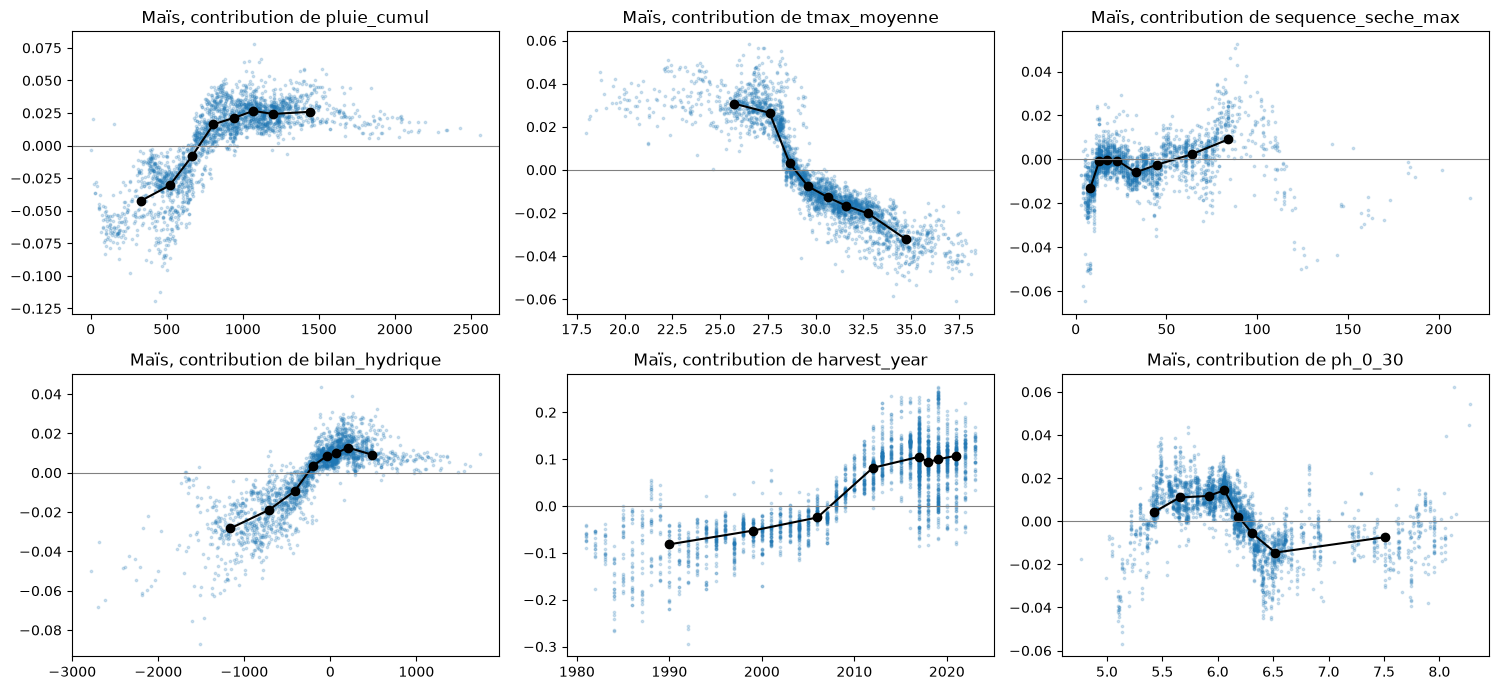

In [6]:
regional = tables["regional"]
mais = regional[regional["partition"].isin(TESTS) & (regional["crop"] == "Maize")].sample(3000, random_state=GRAINE)
modele, description = charger_modele("regional")
contribs_mais, _ = contributions(modele, description, mais)
variables = ["pluie_cumul", "tmax_moyenne", "sequence_seche_max", "bilan_hydrique", "harvest_year", "ph_0_30"]
figure, axes = plt.subplots(2, 3, figsize=(15, 7))
for axe, variable in zip(axes.ravel(), variables):
    courbe = dependance(contribs_mais, mais, variable, 8)
    print(variable)
    display(courbe.round(3))
    axe.scatter(mais[variable], contribs_mais[variable], s=3, alpha=0.2)
    axe.plot(courbe["valeur_mediane"], courbe["contribution_mediane"], color="black", marker="o")
    axe.axhline(0, color="grey", lw=0.8)
    axe.set_title(f"Maïs, contribution de {variable}")
plt.tight_layout()
plt.show()

**Constat**

- La contribution de la pluie de saison croît de -0,043 sous 450 mm à 0,021 vers 950 mm, puis se stabilise vers 0,025. Celle du bilan hydrique croît de -0,028 à 0,013.
- La contribution de la température maximale moyenne décroît de 0,031 vers 26 °C à -0,032 au-delà de 33,5 °C.
- La plus longue séquence sèche et le pH ont des contributions de moins de 0,015 en valeur absolue.
- La contribution de l'année croît de -0,082 vers 1990 à 0,105 en 2017, puis reste stable jusqu'en 2023.

**Analyse**

- Les effets de la pluie et de la chaleur ont le sens et la forme attendus. Le rendement du maïs augmente avec la pluie jusqu'à un plateau et diminue avec la chaleur, d'environ 6 % entre une saison fraîche et une saison chaude.
- Ces effets restent modestes devant la variation des rendements, ce qui confirme la mesure directe de `10_modeling.ipynb`.
- Le plateau de l'année au-delà de 2016 traduit une propriété des arbres de décision, qui n'extrapolent pas au-delà des valeurs vues à l'entraînement. Le modèle reproduit donc le niveau de 2016 pour les années suivantes, sans prolonger la tendance.

### 6. Synthèse

**Résultats**

| Élément | `regional` | `survey` |
|---|---|---|
| Couverture des intervalles à 80 % sur les tests | 84,5 à 85,2 % | 76,9 à 81,5 % |
| Couverture des intervalles à 90 % sur les tests | 92,8 à 92,9 % | 88,1 à 90,8 % |
| Rapport médian des bornes à 80 % | 3,0 | 9,8 |
| Premières familles de facteurs | Culture, pays, climat, sols | Culture, année, pays, sols |

**Limites**

- La couverture des intervalles de `survey` est inférieure au niveau nominal sur les vagues futures et dans quelques pays, dont le Nigeria.
- Les intervalles du tabac de `regional` sont élargis par les erreurs d'unité de la préparation.
- Le modèle ne prolonge pas la tendance des rendements au-delà de 2016, ce qui peut conduire à sous-estimer les années récentes si la hausse se poursuit.
- Les contributions de Shapley décrivent le fonctionnement du modèle et non des effets causaux. Deux variables corrélées peuvent se partager un même effet.